In [30]:
import numpy as np
import os
import matplotlib.pyplot as plt
from sklearn.metrics import mean_squared_error
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import KFold, cross_val_score

In [31]:
buf_fp32_scores = np.load(os.path.join('collected_outputs', 'fp32_scores.npy'))
buf_fp32_boxes = np.load(os.path.join('collected_outputs', 'fp32_boxes.npy'))
buf_uint8_scores = np.load(os.path.join('collected_outputs', 'uint8_scores.npy'))
buf_uint8_boxes = np.load(os.path.join('collected_outputs', 'uint8_boxes.npy'))

buf_fp32_scores.shape, buf_fp32_boxes.shape, buf_uint8_scores.shape, buf_uint8_boxes.shape

((4089, 1), (4089, 6), (4089, 1), (4089, 6))

(0.093302555, 0.08546121, 0.07020283, 0.7146594)

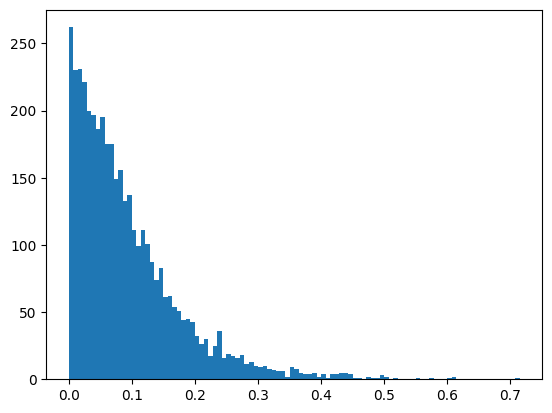

In [32]:
scores_dif = np.abs(buf_fp32_scores - buf_uint8_scores).flatten()
plt.hist(scores_dif, bins=100);
scores_dif.mean(), scores_dif.std(), np.median(scores_dif), scores_dif.max()

Coord dif mean: [5.514849  5.457334  8.029683  8.016644  4.393657  4.2951627]
Coord dif std: [4.250593  4.461773  6.4920444 6.1291795 3.2286184 2.9175632]
Coord dif median: [4.683563  4.7851257 6.270092  6.5905    3.8260193 3.8208275]
Coord dif max: [22.740463 21.465332 34.252747 30.459595 25.786701 23.11087 ]


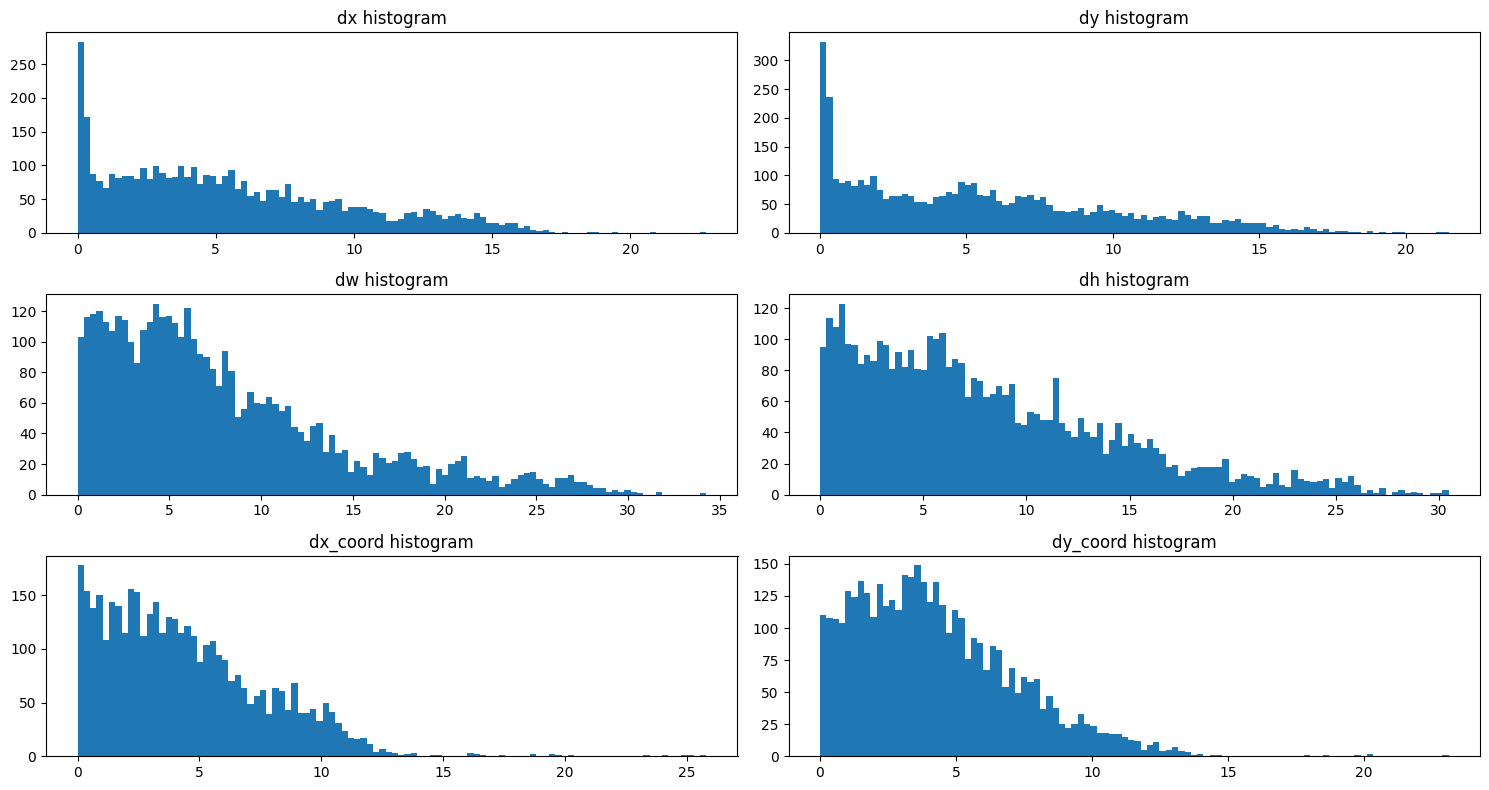

In [33]:
coord_dif = np.abs(buf_fp32_boxes - buf_uint8_boxes)
print("Coord dif mean:", coord_dif.mean(axis=0))
print("Coord dif std:", coord_dif.std(axis=0))
print("Coord dif median:", np.median(coord_dif, axis=0))
print("Coord dif max:", coord_dif.max(axis=0))

plt.figure(figsize=(15, 8))
plt.subplot(3, 2, 1)
plt.hist(coord_dif[:, 0].flatten(), bins=100)
plt.title('dx histogram')
plt.subplot(3, 2, 2)
plt.hist(coord_dif[:, 1].flatten(), bins=100)
plt.title('dy histogram')
plt.subplot(3, 2, 3)
plt.hist(coord_dif[:, 2].flatten(), bins=100)
plt.title('dw histogram')
plt.subplot(3, 2, 4)
plt.hist(coord_dif[:, 3].flatten(), bins=100)
plt.title('dh histogram')
plt.subplot(3, 2, 5)
plt.hist(coord_dif[:, 4].flatten(), bins=100)
plt.title('dx_coord histogram')
plt.subplot(3, 2, 6)
plt.hist(coord_dif[:, 5].flatten(), bins=100)
plt.title('dy_coord histogram')

plt.tight_layout()


In [34]:
for i in range(6):
    X = buf_uint8_boxes[:, i].reshape(-1, 1)
    y = buf_fp32_boxes[:, i]
    
    model = LinearRegression()
    kf = KFold(n_splits=5, shuffle=True, random_state=42)
    scores_stratified = cross_val_score(model, X, y, cv=kf, scoring='neg_mean_squared_error')
    break

In [35]:
# Train linear regression models for all 6 box coordinates
coord_names = ['dx', 'dy', 'dw', 'dh', 'dx_coord', 'dy_coord']
models = []

# First: Train models on full dataset
for i in range(6):
    X = buf_uint8_boxes[:, i].reshape(-1, 1)
    y = buf_fp32_boxes[:, i]
    
    model = LinearRegression(fit_intercept=True)
    model.fit(X, y)
    models.append(model)
    
    print(f"{coord_names[i]}:")
    print(f"  Coef: {model.coef_[0]:.6f}, Intercept: {model.intercept_:.6f}")

print("\n" + "="*50)
print("Model training completed\n")

# Second: Cross-validation evaluation
kf = KFold(n_splits=5, shuffle=True, random_state=42)
cv_scores = []

for i in range(6):
    X = buf_uint8_boxes[:, i].reshape(-1, 1)
    y = buf_fp32_boxes[:, i]
    
    model = LinearRegression(fit_intercept=True)
    scores = cross_val_score(model, X, y, cv=kf, scoring='neg_mean_squared_error')
    cv_scores.append(scores)
    
    print(f"{coord_names[i]} - CV MSE: {-scores.mean():.4f} (+/- {scores.std():.4f})")

# MSE comparison: FP32 vs UINT8 (without regression)
print("\n" + "="*50)
print("MSE: FP32 vs UINT8 (direct conversion)\n")
mse_uint8 = mean_squared_error(buf_fp32_boxes, buf_uint8_boxes, multioutput='raw_values')
for i, name in enumerate(coord_names):
    print(f"{name}: {mse_uint8[i]:.4f}")
print(f"Overall MSE: {mse_uint8.mean():.4f}")

# MSE comparison: FP32 vs Regression predictions (UINT8 as input)
print("\n" + "="*50)
print("MSE: FP32 vs Regression predictions (UINT8 input)\n")
predictions = np.column_stack([models[i].predict(buf_uint8_boxes[:, i].reshape(-1, 1)) for i in range(6)])
mse_regression = mean_squared_error(buf_fp32_boxes, predictions, multioutput='raw_values')
for i, name in enumerate(coord_names):
    print(f"{name}: {mse_regression[i]:.4f}")
print(f"Overall MSE: {mse_regression.mean():.4f}")

# Improvement comparison
print("\n" + "="*50)
print("MSE Improvement (UINT8 -> Regression)\n")
for i, name in enumerate(coord_names):
    improvement = ((mse_uint8[i] - mse_regression[i]) / mse_uint8[i]) * 100
    print(f"{name}: {improvement:.2f}%")
print(f"Overall: {((mse_uint8.mean() - mse_regression.mean()) / mse_uint8.mean()) * 100:.2f}%")

dx:
  Coef: 0.990000, Intercept: 0.941895
dy:
  Coef: 0.984094, Intercept: 0.826164
dw:
  Coef: 0.705880, Intercept: 15.310123
dh:
  Coef: 0.645475, Intercept: 17.121759
dx_coord:
  Coef: 1.003390, Intercept: -0.931152
dy_coord:
  Coef: 1.002818, Intercept: -0.651833

Model training completed

dx - CV MSE: 47.3460 (+/- 2.8822)
dy - CV MSE: 48.2561 (+/- 1.3633)
dw - CV MSE: 75.8749 (+/- 4.8995)
dh - CV MSE: 63.5786 (+/- 3.1793)
dx_coord - CV MSE: 29.5564 (+/- 2.7114)
dy_coord - CV MSE: 26.8803 (+/- 1.9125)

MSE: FP32 vs UINT8 (direct conversion)

dx: 48.4811
dy: 49.6898
dw: 106.6227
dh: 101.8332
dx_coord: 29.7282
dy_coord: 26.9607
Overall MSE: 60.5526

MSE: FP32 vs Regression predictions (UINT8 input)

dx: 47.2944
dy: 48.2009
dw: 75.6744
dh: 63.5417
dx_coord: 29.5277
dy_coord: 26.8207
Overall MSE: 48.5100

MSE Improvement (UINT8 -> Regression)

dx: 2.45%
dy: 3.00%
dw: 29.03%
dh: 37.60%
dx_coord: 0.67%
dy_coord: 0.52%
Overall: 19.89%


In [36]:
buf_fp32_scores[:, :5]

array([[0.24243778],
       [0.36460218],
       [0.2115211 ],
       ...,
       [0.12052725],
       [0.11850783],
       [0.04867251]], dtype=float32)

In [37]:
buf_fp32_boxes[:5]

array([[2.1599323e+02, 2.0968628e-01, 4.7576294e+01, 4.1600639e+01,
        2.2992697e+02, 3.0507935e+01],
       [2.1673070e+02, 3.0862999e-01, 4.6468033e+01, 4.2761650e+01,
        2.2904745e+02, 2.9435486e+01],
       [2.1859109e+02, 5.8332634e-01, 4.5548920e+01, 4.0778862e+01,
        2.3119402e+02, 3.3457062e+01],
       [5.6120407e+01, 3.7047943e+01, 4.4756554e+01, 4.2473961e+01,
        8.8394287e+01, 6.4315018e+01],
       [2.7441077e+02, 1.9996220e+02, 4.5327454e+01, 4.1882690e+01,
        2.8597266e+02, 2.1075414e+02]], dtype=float32)

In [38]:
predictions[: 5]

array([[215.18289   ,   0.82616425,  47.753857  ,  46.78918   ,
        227.737     ,  30.075941  ],
       [215.18289   ,   0.82616425,  47.753857  ,  46.78918   ,
        227.737     ,  30.075941  ],
       [215.18289   ,   0.82616425,  47.753857  ,  46.78918   ,
        237.34492   ,  30.075941  ],
       [ 61.61191   ,  30.980207  ,  47.753857  ,  46.78918   ,
         93.226326  ,  60.803715  ],
       [275.8529    , 198.71207   ,  47.753857  ,  46.78918   ,
        289.22763   , 218.28354   ]], dtype=float32)